# integrantes
- Guilherme Schnekenberg Teixeira (RA00336189)
- Luís Augusto Coelho de Souza (RA00331675)

# projeto escolhido: projeto 1 - classificador automático de tickets de suporte

recebe e-mails de clientes em qualquer idioma e extrai, de forma estruturada (Pydantic), **categoria**, **gravidade**, **sentimento** e **idioma**, para direcionar cada ticket ao setor correto.

**stack:** Python + biblioteca openai + **Gemini API (free tier)** + pandas + seaborn.

> **limitações do free tier do Gemini:**
> - **privacidade:** o Google pode usar o que é enviado para melhorar os produtos dele. portanto, os e-mails deste notebook são fictícios
> - **limite de uso:** há limite de requisições por minuto e por dia. o notebook faz poucas chamadas; se aparecer 429, espere um minuto e rode de novo

## **setup**

usamos a **Gemini API (free tier)** pela biblioteca openai. o Gemini fala o mesmo protocolo *Chat Completions* da OpenAI, então só mudam a chave, a base_url e o nome do modelo. instruções para configuração:

1. gerar a chave em **aistudio.google.com --> Get API key** (grátis)
2. no Colab, abrir o painel **Secrets** e criar `GEMINI_API_KEY` com a chave

In [1]:
%pip install -q openai pandas seaborn matplotlib pydantic

In [3]:
from typing import Literal

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field
from IPython.display import display
from google.colab import userdata
from openai import OpenAI

sns.set_theme(style="whitegrid", context="notebook")

client = OpenAI(
    api_key=userdata.get("GEMINI_API_KEY"), # Secrets do Colab
    base_url="https://generativelanguage.googleapis.com/v1beta/openai/",
    max_retries=6, # tenta de novo sozinho em caso de 429
)
MODEL = "gemini-3.5-flash-lite"

In [8]:
# testa conexão listando os modelos

for m in client.models.list():
    print(m.id)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-omni-1.2-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/gemini-4-carbon
models/gemi

### **dados:  emails sintéticos em diferentes línguas**
categorias de tópicos: [bugs, faturamento, login]

In [5]:
# e-mails em diferentes línguas, sobre os tópicos
emails = [
    "Não consigo entrar na minha conta desde ontem, diz que a senha está errada mas acabei de redefinir.",
    "Seit dem letzten Update stürzt die App beim Öffnen der Einstellungen jedes Mal ab.",
    "I was charged twice for my subscription this month. Please refund one of the payments.",
    "O app fecha sozinho toda vez que tento anexar um arquivo PDF. Uso Android 15.",
    "Hola, la factura de octubre tiene un valor diferente al plan que contraté.",
    "URGENTE: o sistema de pagamentos está fora do ar e nenhum cliente nosso consegue finalizar compras!",
    "The export to CSV button does nothing when I click it. Not urgent, just letting you know.",
    "Ich habe meine Kündigung vor zwei Monaten geschickt, aber Sie buchen immer noch jeden Monat ab.",
    "Recebi um código de verificação por SMS que não pedi. Alguém está tentando acessar minha conta?",
    "Gostaria de saber se posso pagar a anuidade em 3 vezes no cartão.",
    "After the last update, the dashboard takes more than a minute to load. Very frustrating.",
    "Mon compte est bloqué après trois tentatives de connexion. Comment le débloquer ?",
    "Vocês cobraram uma taxa de cancelamento que não estava no contrato. Quero o estorno.",
    "Great product overall! Small bug: dark mode resets every time I restart the app.",
    "Ich bekomme beim Login ständig die Meldung 'Ungültiger Code', obwohl ich den neuesten SMS-Code eingebe.",
]

### **chamada do modelo**

In [6]:
class Ticket(BaseModel):
    id: int
    language: str = Field(description="ISO 639-1 code of the email language, e.g. pt, en, es, fr")
    category: Literal["bug", "billing", "login"]
    severity: Literal["low", "medium", "high", "critical"]
    sentiment: Literal["positive", "neutral", "negative"]
    summary_pt: str = Field(description="Resumo em português, no máximo 10 palavras")

class TicketBatch(BaseModel):
    tickets: list[Ticket]

response = client.chat.completions.parse(
    model=MODEL,
    messages=[
        {"role": "system", "content": (
            "You are a customer-support triage system. Classify each email. "
            "category: bug = product malfunction; billing = charges, invoices, payments; "
            "login = access, passwords, account lock, suspicious access. "
            "severity: critical = many users affected or security risk; high = user blocked; "
            "medium = feature broken with workaround; low = minor issue or question. "
            "Return exactly one item per email, keeping its id."
        )},
        {"role": "user", "content": "\n".join(f"{i}: {text}" for i, text in enumerate(emails))},
    ],
    response_format=TicketBatch,
)

tickets_df = pd.DataFrame([t.model_dump() for t in response.choices[0].message.parsed.tickets]).set_index("id")
tickets_df["email"] = emails
print("tokens usados:", response.usage.total_tokens)
tickets_df

tokens usados: 1127


,language,category,severity,sentiment,summary_pt,email
id,,,,,,
0,pt,login,high,negative,Usuário não consegue entrar mesmo após redefin...,"Não consigo entrar na minha conta desde ontem,..."
1,de,bug,high,negative,Aplicativo trava ao abrir as configurações.,Seit dem letzten Update stürzt die App beim Öf...
2,en,billing,medium,negative,"Cobrança duplicada na assinatura, solicita ree...",I was charged twice for my subscription this m...
3,pt,bug,medium,negative,App fecha ao anexar arquivo PDF no Android.,O app fecha sozinho toda vez que tento anexar ...
4,es,billing,medium,negative,Fatura de outubro com valor incorreto.,"Hola, la factura de octubre tiene un valor dif..."
5,pt,bug,critical,negative,Sistema de pagamentos fora do ar.,URGENTE: o sistema de pagamentos está fora do ...
6,en,bug,low,neutral,Botão de exportar para CSV não funciona.,The export to CSV button does nothing when I c...
7,de,billing,medium,negative,Cobrança indevida após cancelamento da assinat...,Ich habe meine Kündigung vor zwei Monaten gesc...
8,pt,login,critical,negative,Código de verificação suspeito recebido por SMS.,Recebi um código de verificação por SMS que nã...


### **roteamento para o setor responsável**

In [9]:
SETOR = {"bug": "Engenharia", "billing": "Financeiro", "login": "Segurança / Contas"}
PRIORIDADE = {"critical": 1, "high": 2, "medium": 3, "low": 4}

tickets_df["setor"] = tickets_df["category"].map(SETOR)
fila = tickets_df.sort_values(by="severity", key=lambda s: s.map(PRIORIDADE))

for setor, grupo in fila.groupby("setor", sort=False):
    print(f"\n=== {setor} ({len(grupo)} tickets) ===")
    for i, t in grupo.iterrows():
        print(f"  [{t.severity.upper():8}] #{i} ({t.language}) {t.summary_pt}")


=== Engenharia (6 tickets) ===
  [CRITICAL] #5 (pt) Sistema de pagamentos fora do ar.
  [HIGH    ] #1 (de) Aplicativo trava ao abrir as configurações.
  [MEDIUM  ] #3 (pt) App fecha ao anexar arquivo PDF no Android.
  [LOW     ] #6 (en) Botão de exportar para CSV não funciona.
  [LOW     ] #10 (en) Painel demora para carregar após atualização.
  [LOW     ] #13 (en) Modo escuro reseta ao reiniciar o aplicativo.

=== Segurança / Contas (4 tickets) ===
  [CRITICAL] #8 (pt) Código de verificação suspeito recebido por SMS.
  [HIGH    ] #0 (pt) Usuário não consegue entrar mesmo após redefinir senha.
  [HIGH    ] #11 (fr) Conta bloqueada após três tentativas de login.
  [HIGH    ] #14 (de) Erro de código inválido no login por SMS.

=== Financeiro (5 tickets) ===
  [MEDIUM  ] #2 (en) Cobrança duplicada na assinatura, solicita reembolso.
  [MEDIUM  ] #4 (es) Fatura de outubro com valor incorreto.
  [MEDIUM  ] #7 (de) Cobrança indevida após cancelamento da assinatura.
  [MEDIUM  ] #12 (pt) Cobr

### **análise de resultados**

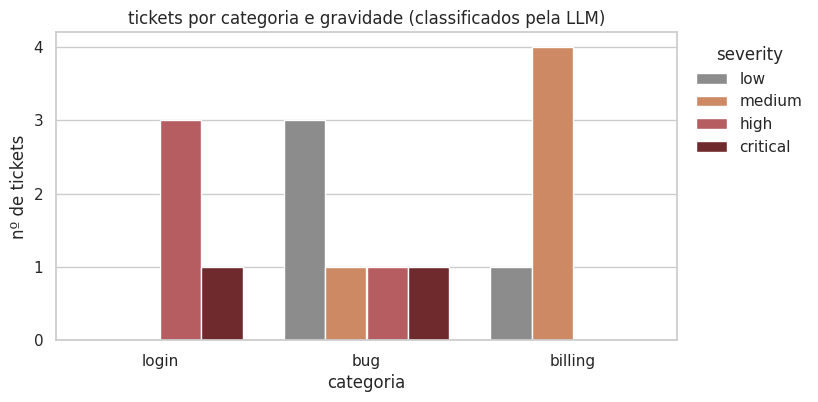

sentiment,negative,neutral,positive
setor,,,
Engenharia,4,1,1
Financeiro,4,1,0
Segurança / Contas,4,0,0


In [11]:
order = ["low", "medium", "high", "critical"]
palette = {"low": "#8c8c8c", "medium": "#dd8452", "high": "#c44e52", "critical": "#7b1e24"}

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=tickets_df, x="category", hue="severity", hue_order=order, palette=palette, ax=ax)
ax.set(title="tickets por categoria e gravidade (classificados pela LLM)", xlabel="categoria", ylabel="nº de tickets")
ax.yaxis.get_major_locator().set_params(integer=True)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.show()

display(tickets_df.groupby(["setor", "sentiment"]).size().unstack(fill_value=0))

### **checagem dos resultados via comparação com "rótulos"**

In [16]:
esperado = ["login", "bug", "billing", "bug", "billing", "bug", "bug", "billing",
            "login", "billing", "bug", "login", "billing", "bug", "login"]

tickets_df["esperado"] = esperado
acerto = (tickets_df["category"] == tickets_df["esperado"]).mean()
print(f"acerto na categoria: {acerto:.0%}")
print("erros:")
tickets_df[tickets_df["category"] != tickets_df["esperado"]][["email", "category", "esperado"]]

acerto na categoria: 100%
erros:


,email,category,esperado
id,,,


### **elaboração de rótulos "humanos" para comparar com o LMM**

In [17]:
esperado_sev = ["high", "high", "medium", "high", "medium", "critical", "low", "high",
                "critical", "low", "medium", "high", "medium", "low", "high"]

esperado_sent = ["negative", "negative", "negative", "negative", "neutral", "negative", "neutral", "negative",
                 "negative", "neutral", "negative", "neutral", "negative", "positive", "negative"]

tickets_df["esperado_sev"] = esperado_sev
tickets_df["esperado_sent"] = esperado_sent

### **matriz de confusão**

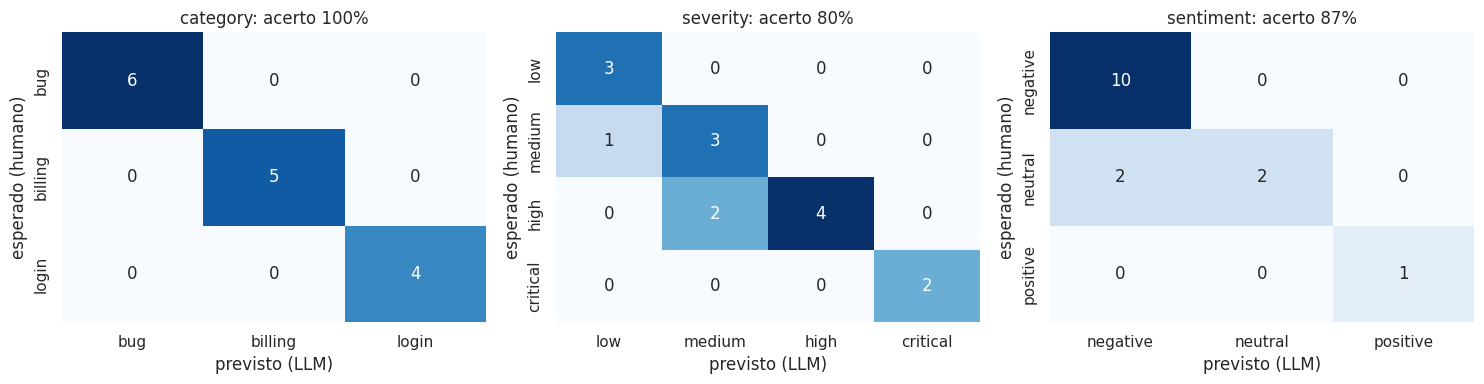

In [18]:
campos = [
    ("category", "esperado", ["bug", "billing", "login"]),
    ("severity", "esperado_sev", ["low", "medium", "high", "critical"]),
    ("sentiment", "esperado_sent", ["negative", "neutral", "positive"]),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (previsto, esperado_col, ordem) in zip(axes, campos):
    matriz = pd.crosstab(tickets_df[esperado_col], tickets_df[previsto]).reindex(index=ordem, columns=ordem, fill_value=0)
    acerto = (tickets_df[previsto] == tickets_df[esperado_col]).mean()
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(title=f"{previsto}: acerto {acerto:.0%}", xlabel="previsto (LLM)", ylabel="esperado (humano)")
plt.tight_layout()
plt.show()

### **discordâncias do modelo**

In [19]:
discordancias = tickets_df[
    (tickets_df["severity"] != tickets_df["esperado_sev"]) |
    (tickets_df["sentiment"] != tickets_df["esperado_sent"])
][["email", "severity", "esperado_sev", "sentiment", "esperado_sent"]]

print(f"{len(discordancias)} e-mails com alguma discordância em gravidade ou sentimento")
discordancias

5 e-mails com alguma discordância em gravidade ou sentimento


,email,severity,esperado_sev,sentiment,esperado_sent
id,,,,,
3,O app fecha sozinho toda vez que tento anexar ...,medium,high,negative,negative
4,"Hola, la factura de octubre tiene un valor dif...",medium,medium,negative,neutral
7,Ich habe meine Kündigung vor zwei Monaten gesc...,medium,high,negative,negative
10,"After the last update, the dashboard takes mor...",low,medium,negative,negative
11,Mon compte est bloqué après trois tentatives d...,high,high,negative,neutral


## **conclusão**

**resultados.** com uma única chamada à API (1.127 tokens), o modelo classificou os 15 e-mails em 5 idiomas e encaminhou cada um ao setor certo.

| campo | acerto |
|---|---|
| categoria | 100% (15/15) |
| idioma | 100% (15/15) |
| sentimento | 87% (13/15) |
| gravidade | 80% (12/15) |

**categoria.** o modelo acertou todos os e-mails, inclusive o caso ambíguo e-mail 5 ("sistema de pagamentos fora do ar"), que fala de pagamento mas é uma falha do sistema e foi classificado como bug crítico. deixar claro no prompt o que cada categoria significa foi suficiente para separar as três.

**gravidade.** os 3 erros seguem o mesmo padrão: o modelo deu **um nível abaixo** do nosso, e nunca errou por mais de um nível.
- e-mail 3 (app fecha ao anexar PDF): high --> medium
- e-mail 7 (cobrança depois do cancelamento): high --> medium
- e-mail 10 (dashboard lento): medium --> low

o modelo parece seguir ao pé da letra a regra do prompt ("high = usuário bloqueado"): nesses casos o usuário ainda consegue usar o resto do produto. com isso, a fila do Financeiro ficou sem nenhum ticket high, embora uma cobrança indevida recorrente provavelmente devesse ser priorizada.

**sentimento.** nos 2 erros (e-mails 4 e 11), o modelo marcou como negativos e-mails que, pelo tom educado, nós consideramos neutros. ele parece associar "relatar um problema" a sentimento negativo, enquanto nós olhamos o tom da escrita.

**conclusão.** a LLM é confiável para os campos objetivos (categoria e idioma) e razoável para os subjetivos (gravidade e sentimento). os erros nesses campos são justamente os casos em que nem nós temos certeza do rótulo certo. para um sistema real de triagem, a classificação por categoria poderia ser automática, enquanto a gravidade precisaria de revisão humana ou de um prompt mais detalhado.

**limitações e extensibilidade**
- **amostra pequena:** 15 e-mails, então cada erro vale ~7 pontos percentuais. o próximo passo seria testar com mais e-mails, lidos de um .CSV
- **rótulos de uma só pessoa:** gravidade e sentimento são subjetivos. usar dois ou mais avaliadores mediria a concordância entre humanos
- **uma execução:** rodar várias vezes mostraria se a classificação é estável
- **free tier:** sem privacidade dos dados e com limite de uso. num sistema real, com e-mails de clientes de verdade, seria preciso usar o plano pago